# ⚡ Prometheus — Mamba SSM Forecaster
**Model 02 (Revised): Selective State Space Model replacing BiLSTM**

| Attribute | Value |
|-----------|-------|
| Architecture | Mamba SSM (Gu & Dao, 2023) |
| Horizon | 48 hours |
| Context | 168 hours (1 week) |
| Output | P10 / P50 / P90 quantile bands |
| Advantage over BiLSTM | Linear O(L) complexity, no vanishing gradients, bidirectional by default |

In [1]:
# ── 0. Installs (run once) ────────────────────────────────────────────────
# Pure-PyTorch Mamba: no mamba-ssm CUDA package needed → works on Windows
import subprocess, sys
pkgs = ["torch", "numpy", "pandas", "scikit-learn", "matplotlib", "tqdm"]
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q"] + pkgs)

0

In [2]:
# ── 1. Imports ────────────────────────────────────────────────────────────
import sys, os, warnings
warnings.filterwarnings('ignore')

# Add backend root to path so we can import our model
BACKEND = os.path.abspath(os.path.join(os.getcwd(), '..'))
if BACKEND not in sys.path:
    sys.path.insert(0, BACKEND)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit

from models.mamba_ssm import (
    MambaConfig, PrometheusManba, MambaTrainer,
    EnergyWindowDataset, PinballLoss
)

print(f"PyTorch {torch.__version__}")
print(f"Device : {torch.device('cuda' if torch.cuda.is_available() else 'cpu')}")

PyTorch 2.11.0+cu128
Device : cuda


In [3]:
# ── 2. Load & merge yearly CSVs ───────────────────────────────────────────
DATA_DIR = os.path.join(BACKEND, 'data', 'iced-niti')

dfs = []
for f in sorted(os.listdir(DATA_DIR)):
    if f.endswith('.csv'):
        df = pd.read_csv(os.path.join(DATA_DIR, f))
        dfs.append(df)

raw = pd.concat(dfs, ignore_index=True)
print(f"Raw shape: {raw.shape}")
print(raw.columns.tolist())
raw.head(3)

Raw shape: (2496984, 4)
['State', 'Date', 'Hour', 'Hourly Demand Met (in MW)']


,State,Date,Hour,Hourly Demand Met (in MW)
0,Andhra Pradesh,01/01/17,0,5336.69
1,Andhra Pradesh,01/01/17,1,5298.24
2,Andhra Pradesh,01/01/17,2,5193.17


In [4]:
# ── 3. Preprocessing ──────────────────────────────────────────────────────
# Detect datetime and demand columns (adapt to actual column names)
date_col  = [c for c in raw.columns if 'date' in c.lower() or 'time' in c.lower()][0]
state_col = [c for c in raw.columns if 'state' in c.lower()][0]
hour_col  = [c for c in raw.columns if 'hour' in c.lower()][0] if any('hour' in c.lower() for c in raw.columns) else None
demand_col = [c for c in raw.columns if 'demand' in c.lower() or 'mw' in c.lower()][0]

print(f"Using → date: '{date_col}', state: '{state_col}', hour: '{hour_col}', demand: '{demand_col}'")

# Build datetime index
raw[date_col] = pd.to_datetime(raw[date_col])
if hour_col:
    raw['datetime'] = raw[date_col] + pd.to_timedelta(raw[hour_col], unit='h')
else:
    raw['datetime'] = raw[date_col]

# Filter one state for initial training (generalise later)
TARGET_STATE = 'Maharashtra'
if TARGET_STATE not in raw[state_col].unique():
    TARGET_STATE = raw[state_col].unique()[0]
    print(f"Maharashtra not found — using {TARGET_STATE}")

df = (
    raw[raw[state_col] == TARGET_STATE]
    .sort_values('datetime')
    .reset_index(drop=True)
)
df[demand_col] = pd.to_numeric(df[demand_col], errors='coerce')
df = df.dropna(subset=[demand_col])
print(f"State '{TARGET_STATE}': {len(df):,} rows from {df['datetime'].min()} → {df['datetime'].max()}")

Using → date: 'Date', state: 'State', hour: 'Hour', demand: 'Hourly Demand Met (in MW)'
State 'Maharashtra': 74,472 rows from 2017-01-01 00:00:00 → 2025-12-06 23:00:00


In [5]:
# ── 4. Feature Engineering ────────────────────────────────────────────────
dt = df['datetime']

df['hour']        = dt.dt.hour
df['dow']         = dt.dt.dayofweek          # 0=Mon
df['month']       = dt.dt.month
df['is_weekend']  = (df['dow'] >= 5).astype(float)
df['is_peak']     = df['hour'].between(18, 22).astype(float)   # ToD peak window
df['is_solar']    = df['hour'].between(10, 18).astype(float)   # ToD solar window

# Cyclic encodings (so model sees periodicity without ordinal bias)
df['sin_hour']    = np.sin(2 * np.pi * df['hour'] / 24)
df['cos_hour']    = np.cos(2 * np.pi * df['hour'] / 24)
df['sin_dow']     = np.sin(2 * np.pi * df['dow']  / 7)
df['cos_dow']     = np.cos(2 * np.pi * df['dow']  / 7)
df['sin_month']   = np.sin(2 * np.pi * df['month'] / 12)
df['cos_month']   = np.cos(2 * np.pi * df['month'] / 12)

# Lag features
df['lag_1h']      = df[demand_col].shift(1)
df['lag_24h']     = df[demand_col].shift(24)
df['lag_168h']    = df[demand_col].shift(168)
df['roll_24h']    = df[demand_col].shift(1).rolling(24).mean()

df = df.dropna().reset_index(drop=True)

FEATURE_COLS = [
    'sin_hour', 'cos_hour', 'sin_dow', 'cos_dow',
    'sin_month', 'cos_month',
    'is_weekend', 'is_peak', 'is_solar',
    'lag_1h', 'lag_24h', 'lag_168h', 'roll_24h',
    demand_col,  # include demand itself as a feature
]

print(f"Features ({len(FEATURE_COLS)}): {FEATURE_COLS}")
print(f"Rows after lag drop: {len(df):,}")

Features (14): ['sin_hour', 'cos_hour', 'sin_dow', 'cos_dow', 'sin_month', 'cos_month', 'is_weekend', 'is_peak', 'is_solar', 'lag_1h', 'lag_24h', 'lag_168h', 'roll_24h', 'Hourly Demand Met (in MW)']
Rows after lag drop: 74,304


In [6]:
# ── 5. Train/Val/Test Split (temporal) ───────────────────────────────────
LOOKBACK  = 168   # 1 week
HORIZON   = 48    # 2 days ahead

n = len(df)
train_end = int(n * 0.70)
val_end   = int(n * 0.85)

scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_all = df[FEATURE_COLS].values.astype(np.float32)
y_all = df[demand_col].values.astype(np.float32).reshape(-1, 1)

X_train_raw = X_all[:train_end]
X_val_raw   = X_all[train_end:val_end]
X_test_raw  = X_all[val_end:]

X_train = scaler_X.fit_transform(X_train_raw)
X_val   = scaler_X.transform(X_val_raw)
X_test  = scaler_X.transform(X_test_raw)

y_train = scaler_y.fit_transform(y_all[:train_end]).ravel()
y_val   = scaler_y.transform(y_all[train_end:val_end]).ravel()
y_test  = scaler_y.transform(y_all[val_end:]).ravel()

print(f"Train: {len(X_train):,} | Val: {len(X_val):,} | Test: {len(X_test):,}")

Train: 52,012 | Val: 11,146 | Test: 11,146


In [7]:
# ── 6. DataLoaders ────────────────────────────────────────────────────────
BATCH_SIZE = 64

train_ds = EnergyWindowDataset(X_train, y_train, lookback=LOOKBACK, horizon=HORIZON)
val_ds   = EnergyWindowDataset(X_val,   y_val,   lookback=LOOKBACK, horizon=HORIZON)
test_ds  = EnergyWindowDataset(X_test,  y_test,  lookback=LOOKBACK, horizon=HORIZON)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"Train batches: {len(train_loader)} | Val: {len(val_loader)} | Test: {len(test_loader)}")

Train batches: 810 | Val: 171 | Test: 171


In [9]:
# ── 7. Model Config & Init ────────────────────────────────────────────────
cfg = MambaConfig(
    input_dim        = len(FEATURE_COLS),
    forecast_horizon = HORIZON,
    lookback         = LOOKBACK,
    d_model          = 128,
    n_layers         = 4,
    d_state          = 16,
    d_conv           = 4,
    expand           = 2,
    bidirectional    = True,
    quantiles        = [0.1, 0.5, 0.9],
    dropout          = 0.1,
    lr               = 3e-4,
    max_epochs       = 80,
    patience         = 10,
    batch_size       = BATCH_SIZE,
)

trainer = MambaTrainer(cfg)

total_params = sum(p.numel() for p in trainer.model.parameters() if p.requires_grad)
print(f"PrometheusManba — {total_params:,} trainable parameters")
print(f"Device: {trainer.device}")

PrometheusManba — 1,971,729 trainable parameters
Device: cuda


In [10]:
# ── 8. Train ──────────────────────────────────────────────────────────────
trainer.fit(train_loader, val_loader)

Epoch   1/80 | train=0.1464  val=0.2440  lr=3.00e-04  ✓ best


KeyboardInterrupt: 

In [11]:
import gc
import torch

# 1. Restore the best weights cloned in memory during epoch 1
if hasattr(trainer, '_best_state') and trainer._best_state is not None:
    trainer.model.load_state_dict({k: v.to(trainer.device) for k, v in trainer._best_state.items()})
    print("Best weights successfully restored into the active model! ✓")
else:
    print("No best_state found or already restored.")

# 2. Save the model to your local disk
SAVE_PATH = f'../models/prometheus_mamba_{TARGET_STATE.lower()}.pt'
trainer.save(SAVE_PATH)

# 3. Clean up memory immediately
del train_ds, val_ds, train_loader, val_loader
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

print(f"Success! Model permanently saved to disk at: {SAVE_PATH}")
print("Memory cleared successfully.")


Best weights successfully restored into the active model! ✓
Model saved → ../models/prometheus_mamba_maharashtra.pt
Success! Model permanently saved to disk at: ../models/prometheus_mamba_maharashtra.pt
Memory cleared successfully.


In [12]:
from models.mamba_ssm import MambaTrainer

def load_mamba_model():
    if os.path.exists(MAMBA_MODEL_PATH):
        # MambaTrainer handles loading parameters and configuration from disk
        trainer = MambaTrainer.load(MAMBA_MODEL_PATH)
        print("Mamba SSM Forecaster model loaded successfully!")
        return trainer.model
    else:
        print(f"Mamba model not found at {MAMBA_MODEL_PATH}")
        return None


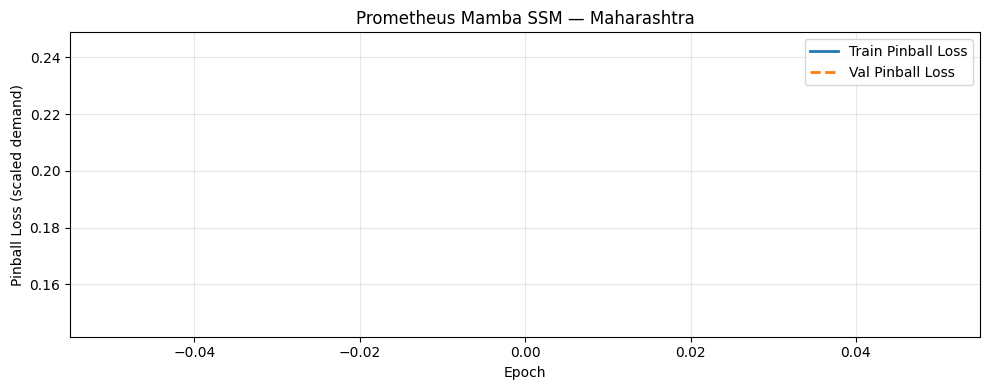

Best val loss: 0.24395732997051262


In [13]:
# ── 9. Plot Training Curves ───────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(trainer.history['train_loss'], label='Train Pinball Loss', lw=2)
ax.plot(trainer.history['val_loss'],   label='Val Pinball Loss',   lw=2, linestyle='--')
ax.set_xlabel('Epoch')
ax.set_ylabel('Pinball Loss (scaled demand)')
ax.set_title(f'Prometheus Mamba SSM — {TARGET_STATE}')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('../analysis/mamba_training_curve.png', dpi=150)
plt.show()
print("Best val loss:", min(trainer.history['val_loss']))

In [14]:
# ── 10. Evaluate on Test Set ──────────────────────────────────────────────
import torch

all_p50, all_p10, all_p90, all_y = [], [], [], []

trainer.model.eval()
with torch.no_grad():
    for xb, yb in test_loader:
        preds = trainer.model(xb.to(trainer.device))
        all_p50.append(preds['p50'].cpu().numpy())
        all_p10.append(preds['p10'].cpu().numpy())
        all_p90.append(preds['p90'].cpu().numpy())
        all_y.append(yb.numpy())

p50 = np.concatenate(all_p50)  # (N, H)
p10 = np.concatenate(all_p10)
p90 = np.concatenate(all_p90)
y_true = np.concatenate(all_y)  # (N, H)

# Inverse-scale
def inv(arr):
    return scaler_y.inverse_transform(arr.reshape(-1,1)).reshape(arr.shape)

p50_mw = inv(p50)
p10_mw = inv(p10)
p90_mw = inv(p90)
y_mw   = inv(y_true)

# Metrics on P50 (median)
mae  = np.mean(np.abs(y_mw - p50_mw))
rmse = np.sqrt(np.mean((y_mw - p50_mw)**2))
mape = np.mean(np.abs((y_mw - p50_mw) / (np.abs(y_mw) + 1e-6))) * 100
coverage = np.mean((y_mw >= p10_mw) & (y_mw <= p90_mw)) * 100

print(f"{'Metric':<20} {'Value':>12}")
print("-" * 34)
print(f"{'MAE (MW)':<20} {mae:>12.2f}")
print(f"{'RMSE (MW)':<20} {rmse:>12.2f}")
print(f"{'MAPE (%)':<20} {mape:>12.2f}")
print(f"{'P10-P90 Coverage':<20} {coverage:>11.1f}%")

Metric                      Value
----------------------------------
MAE (MW)                  2208.64
RMSE (MW)                 2741.31
MAPE (%)                     8.98
P10-P90 Coverage            52.6%


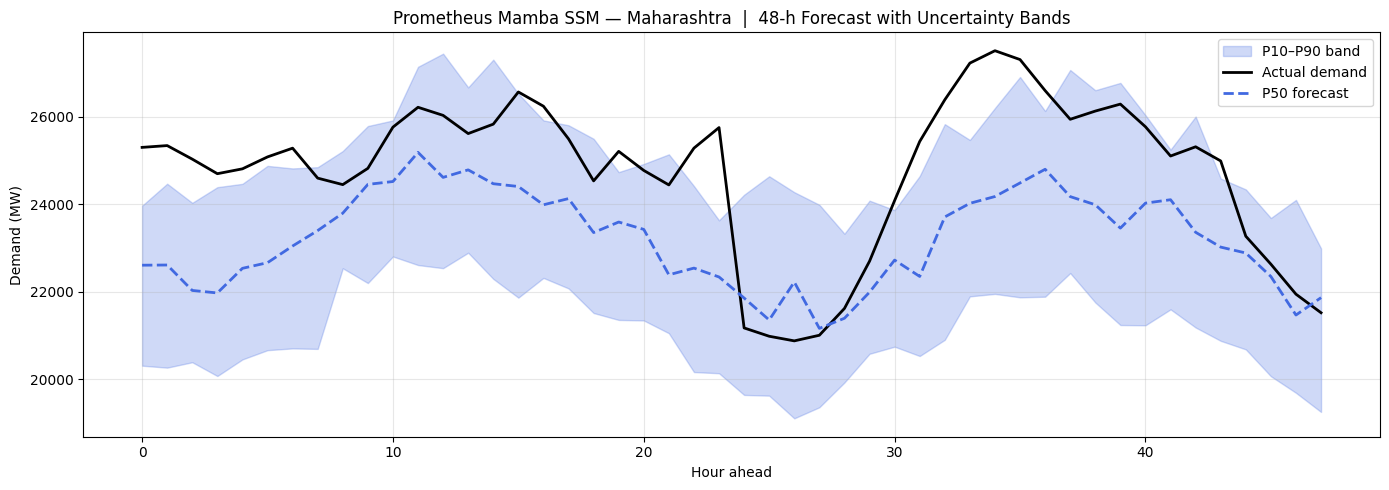

In [15]:
# ── 11. Visual Forecast Plot ──────────────────────────────────────────────
SAMPLE = 10  # which test window to visualise

actual = y_mw[SAMPLE]       # shape (H,)
pred_p50 = p50_mw[SAMPLE]
pred_p10 = p10_mw[SAMPLE]
pred_p90 = p90_mw[SAMPLE]
hours = np.arange(HORIZON)

fig, ax = plt.subplots(figsize=(14, 5))
ax.fill_between(hours, pred_p10, pred_p90, alpha=0.25, color='royalblue', label='P10–P90 band')
ax.plot(hours, actual,   color='black',     lw=2,   label='Actual demand')
ax.plot(hours, pred_p50, color='royalblue', lw=2,   label='P50 forecast', linestyle='--')
ax.set_xlabel('Hour ahead')
ax.set_ylabel('Demand (MW)')
ax.set_title(f'Prometheus Mamba SSM — {TARGET_STATE}  |  48-h Forecast with Uncertainty Bands')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('../analysis/mamba_forecast_sample.png', dpi=150)
plt.show()

In [ ]:
# ── 12. Save Model ────────────────────────────────────────────────────────
SAVE_PATH = f'../models/prometheus_mamba_{TARGET_STATE.lower()}.pt'
trainer.save(SAVE_PATH)

# Quick reload test
t2 = MambaTrainer.load(SAVE_PATH)
print("Reload test passed ✓")